In [2]:
from pathlib import Path

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

DATASET_DIR = Path(
    r"E:\SEM5\ERA\ERA_Project\Brain_Tumor\data"
)

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

OUTPUT_DIR = DATASET_DIR / "preprocessing_experiment"

MASK_DIR = OUTPUT_DIR / "masks"

PROCESSED_DIR = OUTPUT_DIR / "processed"

for directory in [
    OUTPUT_DIR,
    MASK_DIR,
    PROCESSED_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = sorted([
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir()
])

IMG_SIZE = (224, 224)

print("Classes:", CLASS_NAMES)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [3]:
def extract_brain_mask(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    # Remove low-intensity background
    _, mask = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Morphological cleanup
    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    # Retain largest connected component
    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    if num_labels <= 1:
        return np.zeros_like(gray)

    largest_component = (
        1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    )

    brain_mask = np.zeros_like(gray)

    brain_mask[
        labels == largest_component
    ] = 255

    return brain_mask

In [4]:
def preprocess_mri(image):

    image = cv2.resize(
        image,
        IMG_SIZE
    )

    mask = extract_brain_mask(image)

    # Apply foreground mask
    extracted = cv2.bitwise_and(
        image,
        image,
        mask=mask
    )

    # Intensity normalization
    normalized = extracted.astype(
        np.float32
    ) / 255.0

    return image, mask, extracted, normalized

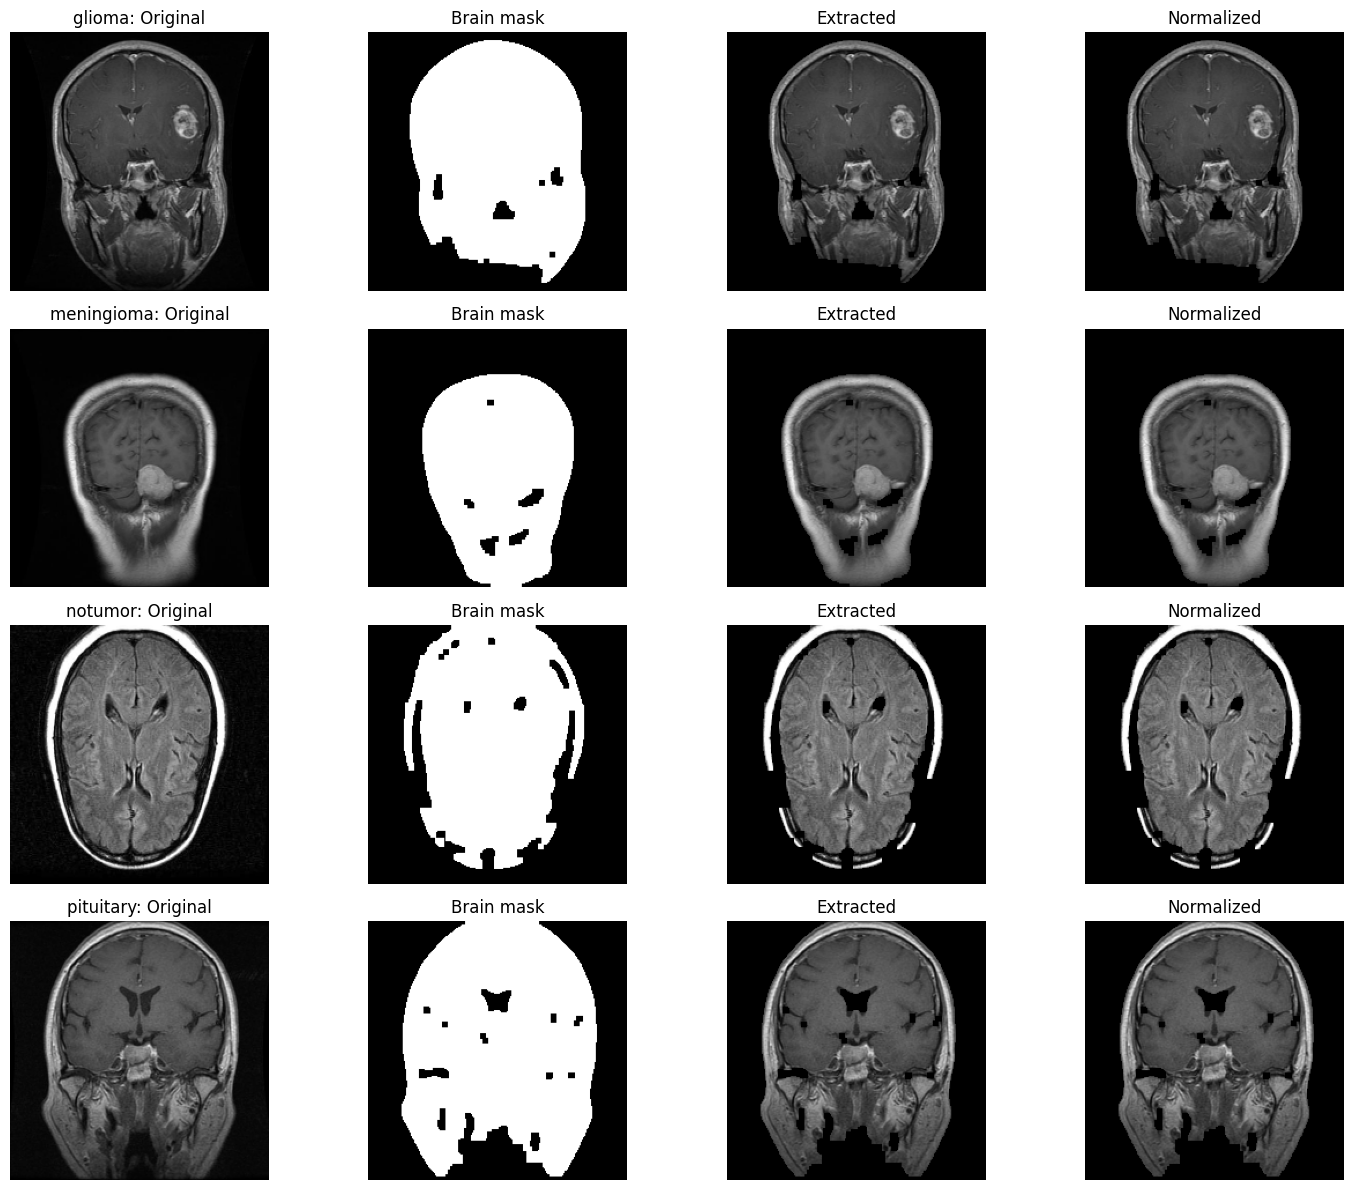

In [5]:
import random

fig, axes = plt.subplots(
    4, 4,
    figsize=(15, 12)
)

for row, class_name in enumerate(CLASS_NAMES):

    class_dir = TRAIN_DIR / class_name

    images = list(class_dir.glob("*.jpg"))

    image_path = random.choice(images)

    image = cv2.imread(str(image_path))

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    original, mask, extracted, normalized = (
        preprocess_mri(image)
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{class_name}: Original"
    )

    axes[row, 1].imshow(
        mask,
        cmap="gray"
    )
    axes[row, 1].set_title("Brain mask")

    axes[row, 2].imshow(extracted)
    axes[row, 2].set_title("Extracted")

    axes[row, 3].imshow(normalized)
    axes[row, 3].set_title("Normalized")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
def calculate_mask_metrics(mask):

    total_pixels = mask.size

    foreground_pixels = np.count_nonzero(
        mask
    )

    occupancy = (
        foreground_pixels / total_pixels
    )

    return occupancy


results = []

for class_name in CLASS_NAMES:

    class_dir = TRAIN_DIR / class_name

    image_paths = list(
        class_dir.glob("*.jpg")
    )

    for image_path in tqdm(
        image_paths,
        desc=class_name
    ):

        image = cv2.imread(
            str(image_path)
        )

        if image is None:
            continue

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        _, mask, _, _ = preprocess_mri(
            image
        )

        occupancy = calculate_mask_metrics(
            mask
        )

        results.append({
            "class": class_name,
            "filename": image_path.name,
            "foreground_occupancy": occupancy
        })


mask_df = pd.DataFrame(results)

print(
    mask_df.groupby("class")[
        "foreground_occupancy"
    ].describe()
)

mask_df.to_csv(
    OUTPUT_DIR / "mask_quality.csv",
    index=False
)

pituitary: 100%|██████████| 1400/1400 [00:09<00:00, 149.23it/s]


             count      mean       std       min       25%       50%  \
class                                                                  
glioma      1400.0  0.437916  0.085180  0.213289  0.379160  0.433504   
meningioma  1400.0  0.445109  0.105873  0.027384  0.380117  0.455776   
notumor     1400.0  0.459711  0.132724  0.007075  0.402842  0.463469   
pituitary   1400.0  0.568717  0.091302  0.025710  0.519736  0.584214   

                 75%       max  
class                           
glioma      0.488037  0.766243  
meningioma  0.512675  0.767738  
notumor     0.549202  0.782884  
pituitary   0.627511  0.776487  


In [7]:
for split_name, split_dir in [
    ("train", TRAIN_DIR),
    ("test", TEST_DIR)
]:

    for class_name in CLASS_NAMES:

        class_dir = split_dir / class_name

        output_class_dir = (
            PROCESSED_DIR /
            split_name /
            class_name
        )

        output_class_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        for image_path in tqdm(
            list(class_dir.glob("*.jpg")),
            desc=f"{split_name}/{class_name}"
        ):

            image = cv2.imread(
                str(image_path)
            )

            if image is None:
                continue

            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )

            _, mask, extracted, _ = (
                preprocess_mri(image)
            )

            output_path = (
                output_class_dir /
                image_path.name
            )

            cv2.imwrite(
                str(output_path),
                cv2.cvtColor(
                    extracted,
                    cv2.COLOR_RGB2BGR
                )
            )

test/pituitary: 100%|██████████| 400/400 [00:03<00:00, 128.26it/s]
